# Step 1 – Ensemble Models (Bagging, Boosting, Stacking, RF + ANN)
**Student:** Indrajith KTN 224078X

**AI use declaration:** This notebook's code was generated with the help of Claude (Anthropic)
and reviewed / run by the student.

Run first (once, in the VS Code terminal):
`pip install pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm catboost statsmodels shap joblib`

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              GradientBoostingRegressor, StackingRegressor)
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 1. Load data
Change `DATA_PATH` if your folder is different.

In [2]:
DATA_PATH = "../data/processed/bird_monthly_data.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "bird_monthly_data.csv"          # fallback: same folder
monthly_data = pd.read_csv(DATA_PATH)
print(monthly_data.shape)
monthly_data.head()

(2454, 13)


,stateProvince,Year,Month,species_richness,observation_count,average_temperature,average_rainfall,average_humidity,average_ndvi,average_wind,average_elevation,average_population_density,average_night_light
0,Ampara,2014,2,125,167,26.592994,0.468443,74.470838,0.532631,3.181257,3.005988,2.643937,0.439339
1,Ampara,2014,3,1,1,27.790000,0.000000,63.800000,0.539900,1.600000,5.000000,1.566867,0.346376
2,Ampara,2014,6,36,41,29.426341,0.510488,72.847805,0.494141,2.739756,5.609756,3.797562,1.234339
3,Ampara,2014,7,46,46,29.790000,0.490000,71.750000,0.444400,2.080000,4.000000,3.116725,2.162765
4,Ampara,2015,3,68,136,28.350000,3.570000,79.250000,0.728900,3.590000,25.000000,0.000000,0.188859


## 2. Sri Lankan monsoon season feature
(replaces the Winter/Spring/Summer/Autumn seasons, which do not exist in Sri Lanka)

In [4]:
def sl_season(m):
    if m in [12, 1, 2]:   return "NE_Monsoon"
    if m in [3, 4]:       return "Inter_Monsoon_1"
    if m in [5, 6, 7, 8, 9]: return "SW_Monsoon"
    return "Inter_Monsoon_2"                      # Oct, Nov

monthly_data["Season"] = monthly_data["Month"].apply(sl_season)
monthly_data = monthly_data.sort_values(["Year", "Month"]).reset_index(drop=True)
monthly_data["Season"].value_counts()

Season
SW_Monsoon         916
NE_Monsoon         702
Inter_Monsoon_1    439
Inter_Monsoon_2    397
Name: count, dtype: int64

## 3. Features and time-based train/test split
`USE_EFFORT = False` -> predict richness from environment only (main experiment).
`USE_EFFORT = True`  -> also give the model `observation_count` (survey effort).

In [5]:
USE_EFFORT = False

base_features = ["stateProvince", "Season", "Year", "Month",
                 "average_temperature", "average_rainfall", "average_humidity",
                 "average_ndvi", "average_wind", "average_elevation",
                 "average_population_density", "average_night_light"]
features = base_features + (["observation_count"] if USE_EFFORT else [])

split_year = 2023
train_data = monthly_data[monthly_data["Year"] < split_year]
test_data  = monthly_data[monthly_data["Year"] >= split_year]

X_train = pd.get_dummies(train_data[features], columns=["stateProvince", "Season"])
X_test  = pd.get_dummies(test_data[features],  columns=["stateProvince", "Season"])
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)
y_train, y_test = train_data["species_richness"], test_data["species_richness"]

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1915, 39)  Test: (539, 39)


## 4. Evaluation helper (MAE, RMSE, R2, MAPE, training time)

In [6]:
results, predictions, trained_models, times = [], {}, {}, {}

def evaluate(name, model, X_tr, X_te, fit=True):
    start = time.time()
    if fit:
        model.fit(X_tr, y_train)
    train_time = time.time() - start
    pred = model.predict(X_te)
    results.append({
        "Model": name,
        "MAE":  mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2":   r2_score(y_test, pred),
        "MAPE": mean_absolute_percentage_error(y_test, pred) * 100,
        "Train_Time_s": round(train_time, 2),
    })
    predictions[name] = pred
    trained_models[name] = model
    times[name] = train_time
    print(f"{name:<28} MAE={results[-1]['MAE']:.2f}  R2={results[-1]['R2']:.3f}  time={train_time:.1f}s")

## 5. Baseline

In [7]:
evaluate("Linear Regression", LinearRegression(), X_train, X_test)

Linear Regression            MAE=26.69  R2=0.436  time=0.1s


## 6. BAGGING: Random Forest, Bagging, ExtraTrees
Light tuning uses `TimeSeriesSplit` (no shuffling, so no future data leaks into training).

In [8]:
tscv = TimeSeriesSplit(n_splits=3)

def tuned(model, params, n_iter=8):
    return RandomizedSearchCV(model, params, n_iter=n_iter, cv=tscv,
                              scoring="neg_mean_absolute_error",
                              random_state=RANDOM_STATE, n_jobs=-1)

rf_search = tuned(RandomForestRegressor(random_state=RANDOM_STATE),
                  {"n_estimators": [100, 200, 300],
                   "max_depth": [None, 6, 10, 15],
                   "min_samples_leaf": [1, 3, 5, 10],
                   "max_features": ["sqrt", 0.5, 1.0]})
evaluate("Random Forest", rf_search, X_train, X_test)
print("Best RF params:", rf_search.best_params_)

Random Forest                MAE=30.13  R2=0.379  time=8.4s
Best RF params: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None}


In [9]:
evaluate("Bagging", BaggingRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
                                     n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
         X_train, X_test)
evaluate("ExtraTrees", ExtraTreesRegressor(n_estimators=200, min_samples_leaf=3,
                                           random_state=RANDOM_STATE, n_jobs=-1),
         X_train, X_test)

Bagging                      MAE=30.00  R2=0.363  time=0.4s
ExtraTrees                   MAE=28.46  R2=0.393  time=0.4s


## 7. BOOSTING: Gradient Boosting, XGBoost, LightGBM, CatBoost

In [10]:
evaluate("Gradient Boosting", GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                                        max_depth=3, random_state=RANDOM_STATE),
         X_train, X_test)

xgb_search = tuned(XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                   {"n_estimators": [100, 200, 400],
                    "learning_rate": [0.02, 0.05, 0.1],
                    "max_depth": [3, 4, 6],
                    "subsample": [0.7, 0.9, 1.0],
                    "colsample_bytree": [0.7, 0.9, 1.0]})
evaluate("XGBoost", xgb_search, X_train, X_test)
print("Best XGB params:", xgb_search.best_params_)

Gradient Boosting            MAE=29.38  R2=0.413  time=1.1s
XGBoost                      MAE=26.71  R2=0.472  time=2.8s
Best XGB params: {'subsample': 0.9, 'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


In [11]:
lgbm_search = tuned(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
                    {"n_estimators": [100, 200, 400],
                     "learning_rate": [0.02, 0.05, 0.1],
                     "num_leaves": [8, 15, 31],
                     "min_child_samples": [5, 10, 20],
                     "subsample": [0.7, 0.9, 1.0],
                     "colsample_bytree": [0.7, 0.9, 1.0]})
evaluate("LightGBM", lgbm_search, X_train, X_test)
print("Best LGBM params:", lgbm_search.best_params_)

LightGBM                     MAE=28.02  R2=0.439  time=2.1s
Best LGBM params: {'subsample': 1.0, 'num_leaves': 15, 'n_estimators': 400, 'min_child_samples': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.9}


In [12]:
evaluate("CatBoost", CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6,
                                       random_state=RANDOM_STATE, verbose=0),
         X_train, X_test)

CatBoost                     MAE=26.44  R2=0.485  time=1.4s


## 8. STACKING
Base models: RF + XGBoost + LightGBM + CatBoost. Meta-model: Ridge.

In [13]:
stacking_model = StackingRegressor(
    estimators=[
        ("rf",   RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                       random_state=RANDOM_STATE, n_jobs=-1)),
        ("xgb",  XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=4,
                              random_state=RANDOM_STATE, n_jobs=-1)),
        ("lgbm", LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=15,
                               random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)),
        ("cat",  CatBoostRegressor(iterations=300, learning_rate=0.05, depth=6,
                                   random_state=RANDOM_STATE, verbose=0)),
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(n_splits=5, shuffle=False),   # un-shuffled folds (rows are already in time order)
)
evaluate("Stacking (RF+XGB+LGBM+Cat)", stacking_model, X_train, X_test)

Stacking (RF+XGB+LGBM+Cat)   MAE=26.48  R2=0.478  time=7.2s


## 9. HYBRID RF + ANN (tabular)
Two versions: (a) simple average, (b) stacking with Ridge meta-model.

In [14]:
ann_model = make_pipeline(StandardScaler(),
                          MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-2,
                                       early_stopping=True, max_iter=1000,
                                       random_state=RANDOM_STATE))
evaluate("ANN (MLP)", ann_model, X_train, X_test)

ANN (MLP)                    MAE=29.04  R2=0.341  time=0.9s


In [15]:
# (a) average of the already-trained RF and ANN
avg_pred = (predictions["Random Forest"] + predictions["ANN (MLP)"]) / 2
results.append({"Model": "Hybrid RF+ANN (average)",
                "MAE": mean_absolute_error(y_test, avg_pred),
                "RMSE": np.sqrt(mean_squared_error(y_test, avg_pred)),
                "R2": r2_score(y_test, avg_pred),
                "MAPE": mean_absolute_percentage_error(y_test, avg_pred) * 100,
                "Train_Time_s": round(times["Random Forest"] + times["ANN (MLP)"], 2)})
predictions["Hybrid RF+ANN (average)"] = avg_pred
print("Hybrid average  MAE =", round(results[-1]["MAE"], 2))

# (b) stacking: RF + ANN -> Ridge
hybrid_stack = StackingRegressor(
    estimators=[("rf", RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                             random_state=RANDOM_STATE, n_jobs=-1)),
                ("ann", make_pipeline(StandardScaler(),
                                      MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-2,
                                                   early_stopping=True, max_iter=1000,
                                                   random_state=RANDOM_STATE)))],
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(n_splits=5, shuffle=False))
evaluate("Hybrid RF+ANN (stacking)", hybrid_stack, X_train, X_test)

Hybrid average  MAE = 25.43
Hybrid RF+ANN (stacking)     MAE=26.21  R2=0.454  time=6.7s


## 10. ONE comparison table (all models)

In [16]:
results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
results_df.insert(0, "Rank", results_df.index + 1)
best_model = results_df.loc[0, "Model"]
print("Best model by MAE:", best_model)
results_df.round(3)

Best model by MAE: Hybrid RF+ANN (average)


,Rank,Model,MAE,RMSE,R2,MAPE,Train_Time_s
0,1,Hybrid RF+ANN (average),25.431,33.272,0.495,90.617,9.31
1,2,Hybrid RF+ANN (stacking),26.210,34.575,0.454,92.276,6.69
2,3,CatBoost,26.442,33.595,0.485,78.695,1.39
3,4,Stacking (RF+XGB+LGBM+Cat),26.477,33.797,0.478,78.422,7.21
4,5,Linear Regression,26.689,35.158,0.436,99.107,0.09
5,6,XGBoost,26.709,34.010,0.472,78.824,2.83
6,7,LightGBM,28.022,35.057,0.439,79.811,2.13
7,8,ExtraTrees,28.462,36.468,0.393,79.461,0.42
8,9,ANN (MLP),29.041,38.001,0.341,105.134,0.90
9,10,Gradient Boosting,29.383,35.853,0.413,87.506,1.06


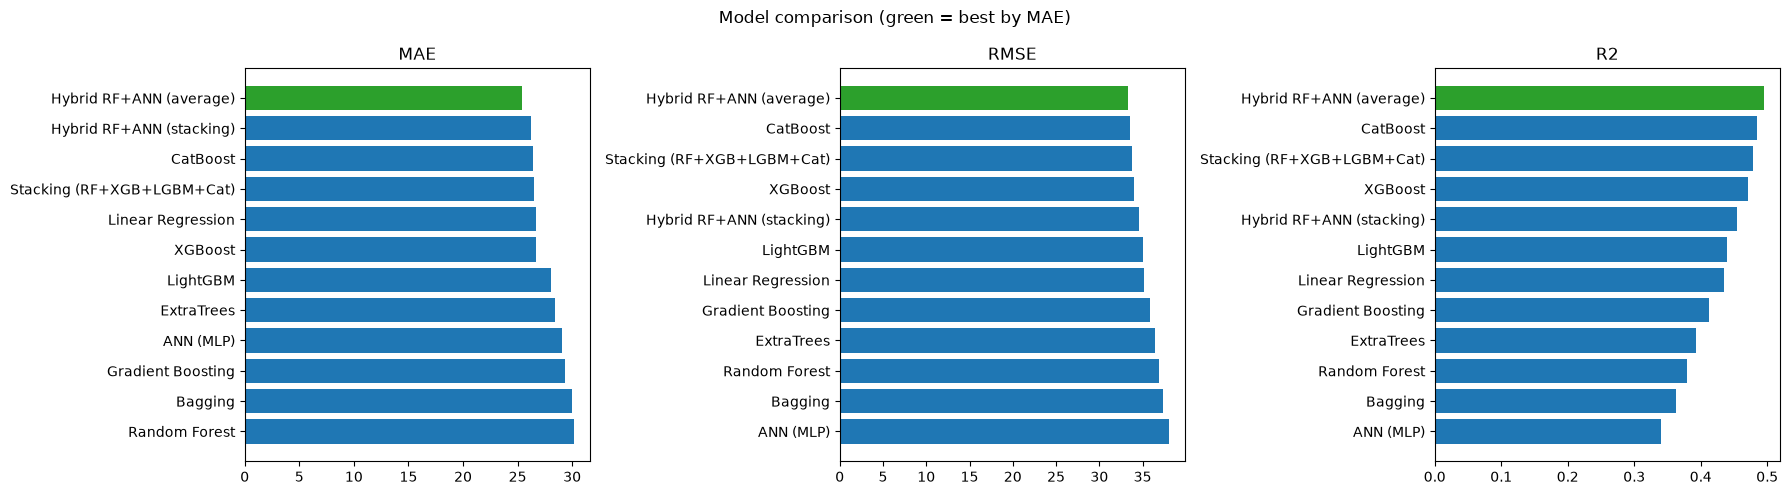

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2"))
    colors = ["tab:green" if m == best_model else "tab:blue" for m in order["Model"]]
    ax.barh(order["Model"], order[metric], color=colors)
    ax.set_title(metric); ax.invert_yaxis()
plt.suptitle("Model comparison (green = best by MAE)")
plt.tight_layout(); plt.show()

## 11. Does survey effort matter? (quick check with Random Forest)
Compares the same RF with and without `observation_count`.

In [18]:
def rf_check(extra):
    cols = base_features + extra
    Xtr = pd.get_dummies(train_data[cols], columns=["stateProvince", "Season"])
    Xte = pd.get_dummies(test_data[cols], columns=["stateProvince", "Season"]).reindex(columns=Xtr.columns, fill_value=0)
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, y_train)
    p = m.predict(Xte)
    return mean_absolute_error(y_test, p), r2_score(y_test, p)

for label, extra in [("Environment only", []), ("Environment + observation_count", ["observation_count"])]:
    mae, r2 = rf_check(extra)
    print(f"{label:<35} MAE={mae:.2f}  R2={r2:.3f}")

Environment only                    MAE=30.90  R2=0.331
Environment + observation_count     MAE=10.19  R2=0.915


## 12. Save results, predictions and models (used by the dashboard)

In [19]:
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

results_df.to_csv("../data/processed/model_results.csv", index=False)

pred_df = pd.DataFrame({"Year": test_data["Year"].values, "Month": test_data["Month"].values,
                        "stateProvince": test_data["stateProvince"].values,
                        "Actual": y_test.values})
for name, p in predictions.items():
    pred_df[name] = p
pred_df.to_csv("../data/processed/test_predictions.csv", index=False)

for name, m in trained_models.items():
    joblib.dump(m, f"../models/{name.replace(' ', '_').replace('+', '').replace('(', '').replace(')', '')}.pkl")
joblib.dump(list(X_train.columns), "../models/feature_columns.pkl")
print("Saved: results, predictions, models")

Saved: results, predictions, models
